In [9]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

In [2]:
data = pd.read_csv("StudentPerformance.csv")

In [3]:
data["math score"] = pd.to_numeric(data["math score"], errors = "coerce")
data["math score"] = data["math score"].fillna(data["math score"].mean())
data["reading score"] = pd.to_numeric(data["reading score"], errors = "coerce")
data["reading score"] = data["reading score"].fillna(data["reading score"].mean())
data["writing score"] = data["writing score"].fillna(data["writing score"].mean())

In [4]:
x = data[["math score", "reading score", "writing score"]]

In [5]:
# necessary
scaler = StandardScaler()

x_scaled = scaler.fit_transform(x)

In [7]:
k = 3

knn = NearestNeighbors(n_neighbors=k + 1)

knn.fit(x_scaled)

distances, indices = knn.kneighbors(x_scaled)
# indices of each nearest neighbor and distance of all neighbors

In [11]:
# Remove the distance to the record itself
distances = distances[:, 1:]  # exclude the datapoint itself from all rows

# Calculate average distance to the 5 nearest neighbors
anomaly_scores = distances.mean(axis=1)

In [22]:
# here we decide how unusual a student must be to qualify as an anomaly.

# percentile means, from all the anomaly score (mean) of all data points, create a split at 99% where the anomaly score of remaining 1% is above it (more distance). 
threshold = np.percentile(anomaly_scores, 97) # whose anomaly score is greater than 99% of remaining

data['Anomaly Score'] = anomaly_scores

data['Anomaly'] = np.where(
    anomaly_scores > threshold,
    -1,
    1
)

In [33]:
anomalies = data[data['Anomaly'] == -1]

print("Total records:", len(data))
print("Anomalies found:", len(anomalies))

print(anomalies)

Total records: 1000
Anomalies found: 30
     gender race/ethnicity parental level of education         lunch  \
17   female        group B            some high school  free/reduced   
59   female        group C            some high school  free/reduced   
76     male        group E            some high school      standard   
131    male        group C            some high school  free/reduced   
149    male        group E          associate's degree  free/reduced   
211    male        group C                some college  free/reduced   
327    male        group A                some college  free/reduced   
338  female        group B            some high school  free/reduced   
339  female        group D            some high school  free/reduced   
357  female        group C                some college  free/reduced   
371  female        group C                some college  free/reduced   
414  female        group C           bachelor's degree  free/reduced   
423  female        group

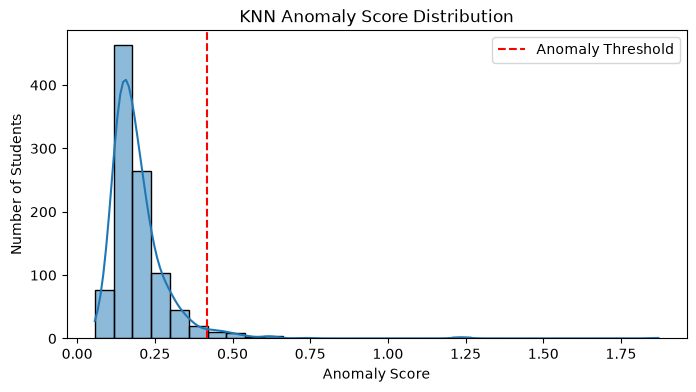

In [38]:
plt.figure(figsize=(8, 4))

sns.histplot(anomaly_scores, bins=30, kde=True)

plt.axvline(
    threshold,
    color='red',
    linestyle='--',
    label='Anomaly Threshold'
)

plt.xlabel('Anomaly Score')
plt.ylabel('Number of Students')
plt.title('KNN Anomaly Score Distribution')

plt.legend()
plt.show()

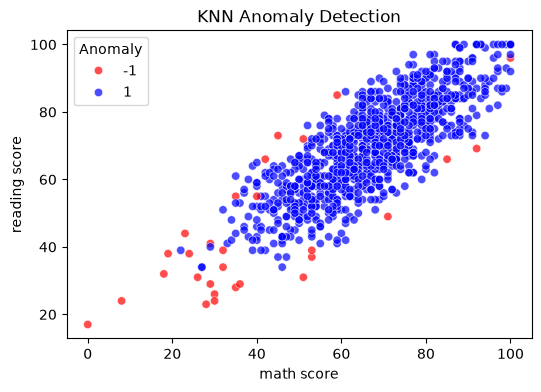

In [35]:
plt.figure(figsize=(6, 4))

sns.scatterplot(
    data=data,
    x='math score',
    y='reading score',
    hue='Anomaly',
    palette={1: 'blue', -1: 'red'},
    alpha=0.7
)

plt.title('KNN Anomaly Detection')
plt.show()

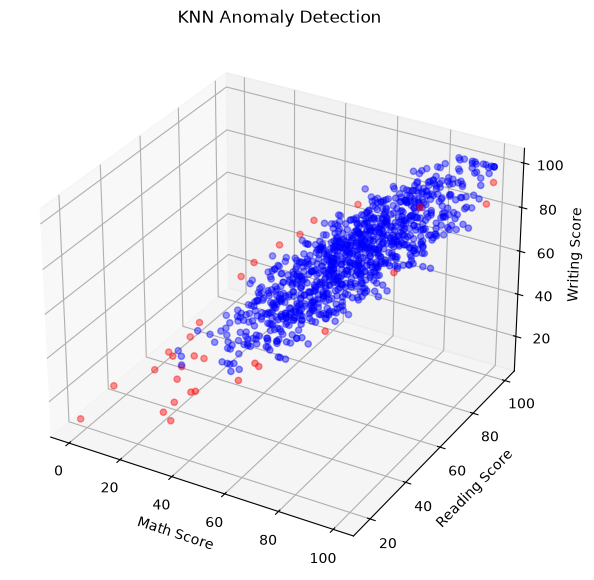

In [37]:
fig = plt.figure(figsize=(10, 7))

#This line creates a 3D plotting area (axes) inside your figure.
ax = fig.add_subplot(111, projection='3d') #1 row, 1 column, and placing the graph at position 1.

scatter = ax.scatter(
    data['math score'],
    data['reading score'],
    data['writing score'],
    c=data['Anomaly'].map({1: 'blue', -1: 'red'}),
    alpha=0.7
)

ax.set_xlabel('Math Score')
ax.set_ylabel('Reading Score')
ax.set_zlabel('Writing Score')

ax.set_title('KNN Anomaly Detection')

plt.show()